# Tropical Cyclones with Neighborhood Filters

A neighborhood reduction replaces the value at every grid element with a reduction
(mean, min, max, sum, ...) over all elements within a great-circle radius `r` of it.
That is a *local* operation, and several standard tropical-cyclone diagnostics are
built from exactly that:

| Diagnostic | Neighborhood expression |
|---|---|
| Storm center | cells where `PS == nb.min(PS)` |
| Pressure deficit | `nb.mean(PS) - PS` |
| Warm-core anomaly | `T - nb.mean(T)` |
| Integrated kinetic energy (IKE) | `nb.sum(ke * area)`, read at the center |
| Peak wind near the center | `nb.max(wind_speed)`, read at the center |
| Wind footprint | `nb.max(on_track) > 0` dilates the track by `r` |
| Rings, radial profiles, wind radii by quadrant | gather the cells around each center, then `where` and `groupby` |

**Part 1** finds and characterizes a real cyclone in a model snapshot.
**Part 2** follows a storm through its life cycle and computes IKE, a wind-field
alternative to ACE. The tutorial data has no winds or time series, so Part 2 uses a
synthetic storm on the same grid.
**Part 3** tracks Hurricane Maria and its neighbors through a 3 km MPAS simulation of
September 2017 on NCAR's HPC systems.

For an introduction to the API itself, see the
[Neighborhood Filter](neighborhood-filter.ipynb) user guide.

In [1]:
import os
import tempfile
import urllib.request
from pathlib import Path

# Downloads and caches (tutorial data, coastlines, best tracks) go here. Set it once,
# e.g. SCRATCH_DIR = Path("/glade/work/<user>/cyclones"); nothing else needs changing.
SCRATCH_DIR = Path(tempfile.gettempdir()) / "uxarray-cyclones"
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)

# Read when uxarray is imported, so it is set before the imports below
os.environ["UXARRAY_TUTORIAL_CACHE_DIR"] = str(SCRATCH_DIR / "tutorial")


def fetch(url):
    # Download once into SCRATCH_DIR and reuse the copy; local paths pass through
    if "://" not in str(url):
        return Path(url)
    path = SCRATCH_DIR / "downloads" / str(url).rsplit("/", 1)[-1]
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
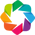

In [2]:
import cartopy
import holoviews as hv
import numpy as np
import pandas as pd
import xarray as xr

import uxarray as ux

# Load the plotting extension up front; some frontends (e.g. VS Code) leave the
# first plot blank if it is loaded in the same cell as the plot.
hv.extension("bokeh")
cartopy.config["data_dir"] = str(SCRATCH_DIR / "cartopy")  # coastline downloads

R_EARTH = 6.371e6  # m


def at(field, n_face):
    # Value of a grid-mapped field at the given face(s). Converting to a plain
    # DataArray lets an index that varies along `time` select pointwise.
    return xr.DataArray(field).isel(n_face=n_face)

## Part 1: A Cyclone in a Model Snapshot

`ne120-tcsubset` is a regional subset of a ~25 km cubed-sphere simulation with a
tropical cyclone off northwest Australia: surface pressure plus temperature and
geopotential height on pressure levels.

In [3]:
ds = ux.tutorial.open_dataset("ne120-tcsubset")
grid = ds.uxgrid
lat, lon = grid.face_lat.values, grid.face_lon.values
ds

<xarray.UxDataset> Size: 301kB
Dimensions:  (n_face: 1417, plev: 26)
Coordinates:
  * plev     (plev) float64 208B 354.5 738.9 1.397e+03 ... 9.706e+04 9.926e+04
    time     object 8B ...
Dimensions without coordinates: n_face
Data variables:
    PS       (n_face) float32 6kB ...
    T        (plev, n_face) float32 147kB ...
    Z3       (plev, n_face) float32 147kB ...

In [4]:
ps_plot = (ds["PS"] / 100).plot.polygons(
    cmap="viridis", clabel="PS (hPa)", title="Surface pressure", width=500, height=450
)
ps_plot

:Image   [x,y]   (x_y PS)

### Build the neighborhood once

The expensive part of a neighborhood reduction is finding the neighbors. Building it
from the grid with `Grid.neighborhood` does that once, after which any number of
variables and reductions reuse it.

This is a regional grid, so neighborhoods near the boundary are cut off and contain
fewer cells. `n_neighbors` shows where: a minimum or mean computed there only sees one
side of the storm, so we mask those cells out.

In [5]:
nb_1deg = grid.neighborhood(r=1.0)
nb_1deg

<Neighborhood on='face centers' r=1.0 n_elements=1417 neighbors_per_element=[24, 63]>

In [6]:
counts = nb_1deg.n_neighbors
interior = counts >= 0.8 * counts.median()

ux.UxDataArray(counts, uxgrid=grid).plot.polygons(
    cmap="cividis",
    title="Cells within 1° (edge cells are truncated)",
    width=500,
    height=450,
)

:Image   [x,y]   (x_y n_neighbors)

### Find the center

A cell is a local minimum if it equals the minimum of its own neighborhood. This is
the same test storm trackers such as TempestExtremes start from.

In [7]:
ps = ds["PS"]
is_min = (ps == nb_1deg.min(ps)) & interior

center = int(np.flatnonzero(is_min.values)[0])
print(f"local minima away from the edge: {int(is_min.sum())}")
print(
    f"center: {-lat[center]:.2f}°S, {lon[center]:.2f}°E, PS = {ps.values[center] / 100:.1f} hPa"
)

ps_plot * hv.Points([(lon[center], lat[center])]).opts(color="red", marker="x", size=14)

local minima away from the edge: 1
center: 17.66°S, 114.54°E, PS = 968.5 hPa


:Overlay
   .Image.I  :Image   [x,y]   (x_y PS)
   .Points.I :Points   [x,y]

### How deep is it?

The pressure deficit is the central pressure relative to its surroundings, and
"surroundings" needs a scale. Measured against larger neighborhoods, the same low
looks deeper, so a tracking threshold always comes with a radius.

In [8]:
for r in [0.5, 1.0, 2.0]:
    depth = grid.neighborhood(r=r).mean(ps) - ps
    print(f"r = {r}°: deficit {depth.values[center] / 100:5.1f} hPa")

r = 0.5°: deficit   8.2 hPa
r = 1.0°: deficit  19.4 hPa
r = 2.0°: deficit  32.4 hPa


### Is it warm-core?

Tropical cyclones have a warm core aloft. Subtracting each level's 2° neighborhood
mean removes the large-scale environment and leaves the local anomaly. The
neighborhood is reused across all 26 pressure levels, which pass through as an
extra dimension.

In [9]:
nb_2deg = grid.neighborhood(r=2.0)
t_anom = ds["T"] - nb_2deg.mean(ds["T"])

profile = at(t_anom, center).sel(plev=slice(10000, None))  # surface to 100 hPa
profile_plot = hv.Curve(
    (profile.values, profile.plev.values / 100), "T anomaly (K)", "Pressure (hPa)"
).opts(invert_yaxis=True, width=300, height=450, title="Above the center")

map_400 = t_anom.sel(plev=40000, method="nearest").plot.polygons(
    cmap="RdBu_r",
    symmetric=True,
    clabel="K",
    title="T anomaly near 400 hPa",
    width=500,
    height=450,
)
profile_plot + map_400

:Layout
   .Curve.I :Curve   [T anomaly (K)]   (Pressure (hPa))
   .Image.I :Image   [x,y]   (x_y T)

The anomaly peaks near 370 hPa, about 8 K warmer than its surroundings, above the
surface center: a classic tropical-cyclone warm core. Together,
the local minimum, the pressure deficit, and the warm core are the usual criteria
for telling a tropical cyclone apart from other lows.

## Part 2: Following a Storm's Life Cycle

ACE (accumulated cyclone energy) sums the square of one number, the peak wind, every
six hours. It cannot tell a compact storm from a broad one with the same peak wind,
even though the broad one moves far more energy and drives a larger storm surge.
**Integrated kinetic energy** (IKE; Powell and Reinhold 2007) integrates the kinetic
energy of all tropical-storm-force wind (≥ 18 m/s) over the area around the center:

$$\mathrm{IKE} = \int_A \tfrac{1}{2} \rho\, |\mathbf{U}|^2 \, dA \quad (\text{1 m deep layer},\ \rho = 1\ \mathrm{kg\,m^{-3}})$$

An integral over a disk around the center is exactly an area-weighted neighborhood
**sum** evaluated at the center.

### A synthetic storm

The tutorial data has no winds and no time series, so we build a storm on the same
grid from the Holland (1980) wind profile, which gives physically consistent
pressure and wind fields. Over 48 hourly steps the storm moves southwest, intensifies
until hour 24, then weakens while its wind field broadens, as storms often do late in
life. A weak, stationary low that is not a cyclone is added to give the tracker
something to reject.

In [10]:
hours = np.arange(49)
time = np.datetime64("2026-01-10T00") + hours.astype("timedelta64[h]")

# Track and life cycle
center_lat = np.linspace(-17.0, -19.0, hours.size)
center_lon = np.linspace(115.5, 112.5, hours.size)
deficit = np.interp(hours, [0, 24, 48], [1500, 5500, 3500])  # Pa
rmax = np.interp(hours, [0, 24, 48], [25e3, 40e3, 70e3])  # radius of max wind, m
shape_b = np.interp(hours, [0, 24, 48], [1.6, 1.6, 1.3])  # Holland B; lower is broader


def holland_storm(t, rho=1.15):
    # Surface pressure and wind components of a Holland (1980) vortex at hour t.
    phi, lam = np.radians(lat), np.radians(lon)
    phi_c, lam_c = np.radians(center_lat[t]), np.radians(center_lon[t])
    hav = (
        np.sin((phi - phi_c) / 2) ** 2
        + np.cos(phi) * np.cos(phi_c) * np.sin((lam - lam_c) / 2) ** 2
    )
    r = 2 * R_EARTH * np.arcsin(np.sqrt(hav)) + 1.0  # +1 m: no division by zero
    x = (rmax[t] / r) ** shape_b[t]
    f = abs(2 * 7.292e-5 * np.sin(phi_c))
    speed = np.sqrt(shape_b[t] / rho * deficit[t] * x * np.exp(-x) + (r * f / 2) ** 2)
    speed -= r * f / 2

    environment = 101000 - 60 * (lat + 18)  # weak north-south gradient, Pa
    pressure = environment - deficit[t] * (1 - np.exp(-x))

    # Clockwise rotation: cyclonic in the Southern Hemisphere
    dx = (lam - lam_c) * np.cos(phi_c) * R_EARTH
    dy = (phi - phi_c) * R_EARTH
    return pressure, speed * dy / r, -speed * dx / r


pressure, u, v = map(np.stack, zip(*(holland_storm(t) for t in hours)))
pressure -= 400 * np.exp(-(((lat + 15) ** 2 + ((lon - 111.5) * 0.96) ** 2) / 2.5**2))


def as_field(values, name, units):
    return ux.UxDataArray(
        values,
        dims=["time", "n_face"],
        coords={"time": time},
        uxgrid=grid,
        name=name,
        attrs={"units": units},
    )


storm_ps = as_field(pressure, "PS", "Pa")
wspd = np.hypot(as_field(u, "U", "m/s"), as_field(v, "V", "m/s")).rename("wind_speed")
wspd

<xarray.UxDataArray 'wind_speed' (time: 49, n_face: 1417)> Size: 555kB
array([[ 0.36710698,  0.39266686,  0.38090584, ...,  1.28569553,
         1.19308945,  1.14945444],
       [ 0.43530365,  0.46580746,  0.4518327 , ...,  1.40154367,
         1.30313497,  1.25643433],
       [ 0.51054973,  0.54654194,  0.53012611, ...,  1.51329879,
         1.40962384,  1.36009133],
       ...,
       [15.59016245, 16.13999097, 16.01222516, ...,  3.90157053,
         3.7778465 ,  3.71070722],
       [16.03063125, 16.56636015, 16.45160601, ...,  3.8860753 ,
         3.76465373,  3.69869657],
       [16.45629815, 16.97478477, 16.87455162, ...,  3.86677337,
         3.74771325,  3.68297576]], shape=(49, 1417))
Coordinates:
  * time     (time) datetime64[s] 392B 2026-01-10 ... 2026-01-12
Dimensions without coordinates: n_face
Attributes:
    units:    m/s

### Track the center

The same test as in Part 1, now applied to all 49 time steps in a single call. The
synthetic fields live on the same grid, so `nb_1deg` and `interior` from Part 1 are
reused as they are. A minimum pressure deficit of 2 hPa separates the cyclone from
the weak low.

In [11]:
is_min = storm_ps == nb_1deg.min(storm_ps)
depth = nb_1deg.mean(storm_ps) - storm_ps
candidates = is_min & interior & (depth > 200)

print("local minima per hour:     ", np.unique(is_min.sum("n_face")))
print("cyclone candidates per hour:", np.unique(candidates.sum("n_face")))

local minima per hour:      [1 2]
cyclone candidates per hour: [1]


In [12]:
# Link candidates into a track: start at the deepest, then step to the nearest
# candidate each hour. Real output would also need to handle gaps and several storms.
track = np.empty(hours.size, dtype=int)
for t in hours:
    found = np.flatnonzero(candidates.values[t])
    if t == 0:
        track[t] = found[np.argmin(storm_ps.values[t, found])]
    else:
        prev = track[t - 1]
        jump = np.hypot(
            lat[found] - lat[prev],
            (lon[found] - lon[prev]) * np.cos(np.radians(lat[prev])),
        )
        track[t] = found[np.argmin(jump)]

track = xr.DataArray(track, dims="time", coords={"time": time})
error = np.hypot(lat[track] - center_lat, lon[track] - center_lon)
print(
    f"largest distance from the true center: {error.max():.2f}° (grid spacing ~0.25°)"
)

largest distance from the true center: 0.18° (grid spacing ~0.25°)


### IKE, peak wind, and storm size

One 3° (~330 km) neighborhood serves three diagnostics at every hour. Its radius
bounds the integral so that other weather systems are not counted; it must be large
enough to contain the storm's gale-force winds, which it is here.

In [13]:
area = grid.face_areas * R_EARTH**2  # m²; face_areas is on the unit sphere
gale = wspd >= 18  # tropical-storm force, m/s
ke = (0.5 * 1.0 * wspd**2).where(gale, 0) * area  # J per 1 m deep layer

nb_storm = grid.neighborhood(r=3.0)

ike = at(nb_storm.sum(ke), track) / 1e12  # TJ
vmax = at(nb_storm.max(wspd), track)  # m/s
gale_radius = np.sqrt(at(nb_storm.sum(gale * area), track) / np.pi) / 1e3  # km

curve = dict(width=300, height=250, tools=["hover"])
(
    hv.Curve((time, vmax.values), "time", "Peak wind (m/s)").opts(**curve)
    + hv.Curve((time, ike.values), "time", "IKE (TJ)").opts(**curve)
    + hv.Curve((time, gale_radius.values), "time", "Gale-force radius (km)").opts(
        **curve
    )
)

:Layout
   .Curve.I   :Curve   [time]   (Peak wind (m/s))
   .Curve.II  :Curve   [time]   (IKE (TJ))
   .Curve.III :Curve   [time]   (Gale-force radius (km))

In [14]:
fixes = time[::6]  # the 6-hourly fixes ACE is built from
vmax_kt = vmax.sel(time=fixes) * 1.94384
pd.DataFrame(
    {
        "peak wind (kt)": vmax_kt.round(0),
        "ACE term (1e4 kt²)": (1e-4 * vmax_kt.where(vmax_kt >= 35, 0) ** 2).round(2),
        "IKE (TJ)": ike.sel(time=fixes).round(1),
    },
    index=pd.Index(fixes, name="time"),
)

,peak wind (kt),ACE term (1e4 kt²),IKE (TJ)
time,,,
2026-01-10 00:00:00,53.0,0.28,3.5
2026-01-10 06:00:00,68.0,0.47,10.5
2026-01-10 12:00:00,81.0,0.65,22.2
2026-01-10 18:00:00,92.0,0.84,38.8
2026-01-11 00:00:00,101.0,1.03,61.9
2026-01-11 06:00:00,94.0,0.88,74.7
2026-01-11 12:00:00,86.0,0.75,81.5
2026-01-11 18:00:00,79.0,0.62,84.2
2026-01-12 00:00:00,71.0,0.51,79.4


The peak wind tops out at hour 24 and falls 30% by hour 48, halving each ACE term.
Over the same period the gale-force wind field keeps expanding and IKE keeps rising,
peaking 18 hours after the peak wind. A diagnostic built on one wind value cannot see
this; one built on the whole wind field can.

### Wind footprint

Which areas felt damaging wind, and how strong? Marking the center at each hour and
taking a neighborhood **max** of that marker dilates it to everything within 3° of
the center. Masking the wind with it before taking the maximum over time keeps other
weather systems out of the footprint. Here the synthetic field has only one storm, so
the mask changes nothing, but on real output it does.

In [15]:
marker = np.zeros(wspd.shape)
marker[hours, track.values] = 1
near_track = nb_storm.max(as_field(marker, "on_track", "1")) > 0

footprint = wspd.where(near_track).max("time").rename("max_wind")
footprint.plot.polygons(
    cmap="inferno",
    clabel="Max wind (m/s)",
    title="48 h wind footprint",
    width=500,
    height=450,
) * hv.Path([np.column_stack([lon[track], lat[track]])]).opts(
    color="white", line_width=2
)

:Overlay
   .Image.I :Image   [x,y]   (x_y max_wind)
   .Path.I  :Path   [x,y]

## Part 3: Hurricane Maria at 3 km

The NSF NCAR Mesoamerica Affinity Group (MAAG) ran MPAS-Atmosphere over
15–30 September 2017 on a limited-area, variable-resolution mesh (6.09 million cells)
that is 3 km over the Caribbean and western Atlantic and 15 km beyond
([GDEX dataset d010077](https://gdex.ucar.edu/datasets/d010077/)). Hourly surface
fields are kept on the native mesh. The model's Maria forms within the run and stays
in the 3 km region until the run ends, when the real Maria was a day from becoming
extratropical. Jose and Lee are active too.

This section tracks every tropical cyclone in the run and computes IKE, peak wind,
radius of maximum wind and gale-force radius by quadrant along each track, then
compares the model's Maria with the National Hurricane Center's best track.

**It needs NCAR's GLADE file system** (Casper or Derecho) and a node with at least
64 GB of memory and as many cores as you can get. Set `MAAG_DIR` to read the files
elsewhere. Expect 5–10 minutes; the timings are summarized at the end.

### Filters where every cell matters, gathers where only a few do

A neighborhood filter computes its reduction at every cell. That cost grows with the
number of cells times the cells per neighborhood, and at 3 km a 3° neighborhood holds
about 45,000 cells. Over this region that is about $10^{10}$ cell pairs per hour, far
too many. So the work is split:

| Pass | Where | Radius | Tool |
|---|---|---|---|
| 1. Pressure minima | every cell | 0.25° (~300 cells) | `Neighborhood.min` |
| 2. Windy area, pressure rise, warm core | each pressure minimum | 2° | gather + `groupby` |
| 3. Link fixes in time | each fix | 1° per hour | nearest fix |
| IKE, wind radii, footprint | each track fix | 3° | gather + `groupby` |

A *gather* collects, for a handful of centers, every cell within `r` as one row per
(center, cell) pair, with the distance and bearing from the center. Disks, radial
profiles, quadrants and masks are then ordinary `where` and `groupby` operations.
uxarray has no gather yet; the one below is a few lines on top of the grid's
`BallTree`, the same search `Neighborhood` uses. (`Neighborhood.reduce` accepts a
custom reduction, but it runs at every cell and sees only values, not distances.)

In [16]:
import glob
import os
import time as clock
from concurrent.futures import ThreadPoolExecutor

import dask
from dask.distributed import Client, LocalCluster, as_completed

# Use the cores this job was allocated, not every core on the node
n_cores = (
    len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
)
dask.config.set(scheduler="threads", num_workers=n_cores)

maag_dirs = [  # GDEX d010077 native-mesh output on GLADE (current and former layout)
    "/glade/campaign/collections/gdex/data/d010077/native_diag",
    "/glade/campaign/collections/rda/data/d010077/native_diag",
]
maag_dir = os.environ.get("MAAG_DIR") or next(
    (d for d in maag_dirs if os.path.isdir(d)), None
)
if maag_dir is None:
    raise FileNotFoundError(
        "MAAG output not found. This section runs on NCAR's GLADE file system; "
        "set MAAG_DIR to use a copy elsewhere."
    )
static_file = f"{maag_dir}/MAAG.static.nc"
HOURS = slice(None)  # all 361 hours; e.g. slice(96, 168) for a quicker first run
diag_files = sorted(glob.glob(f"{maag_dir}/diag.2017-09-*.nc"))[HOURS]

# Degrees. Covers Maria from its formation near 12°N (centers need R_DISK of clearance
# from the edge), and Jose until it moves north of about 38°N
REGION = dict(lon=(-78, -48), lat=(5, 40))
R_MIN = 0.25  # pass 1: lowest pressure within this radius
R_DISK = 2.0  # pass 2: tests over the disk within this radius, eye included
SAMPLE_SPACING = 12  # km; pass 2 averages over a sample of cells about this far apart
WINDY_AREA = (
    0.3  # pass 2: least fraction of the disk's area with wind of 17 m/s or more
)
PRESSURE_RISE = (
    300  # pass 2: least excess of the disk's mean pressure over the center's, Pa
)
WARM_CORE = (
    1.0  # pass 2: least excess of the center's 250 hPa temperature over the disk's, K
)
R_IKE = 3.0  # IKE and wind radii
RMW_BIN = 0.05  # radial bin for the radius of maximum wind
LINK_SPEED, MAX_GAP, MIN_HOURS = 1.0, 3, 24  # degrees per hour, hours, hours
BATCH = 100  # centers gathered at once; each batch holds up to ~0.5 GB at 3 km
N_READERS = min(n_cores, 16)  # processes reading the hourly files
N_THREADS = min(n_cores, 8)  # gather batches in flight at once

# NHC best tracks ("b-decks") of the storms active in the run
BDECKS = {
    name: f"https://ftp.nhc.noaa.gov/atcf/archive/2017/bal{number}2017.dat.gz"
    for name, number in [("JOSE", 12), ("LEE", 14), ("MARIA", 15)]
}
timings = {}
print(f"{len(diag_files)} hourly files; {n_cores} cores")

361 hourly files; 8 cores


### The mesh and the hourly fields

The mesh is cut down to the region by cell center. Each hourly file holds one field
per variable over all 6.09 million cells; it is read once and only the region is kept,
about 6.5 GB for all 361 hours. The files are read by a pool of separate processes; the
dask dashboard link it prints shows them at work.

In [17]:
start = clock.perf_counter()
mesh = ux.open_grid(static_file)
in_region = (
    (mesh.face_lon >= REGION["lon"][0])
    & (mesh.face_lon <= REGION["lon"][1])
    & (mesh.face_lat >= REGION["lat"][0])
    & (mesh.face_lat <= REGION["lat"][1])
)
cells = np.flatnonzero(in_region.values)
region = mesh.isel(n_face=cells)
del mesh, in_region  # the full 6.09M-cell mesh is no longer needed
lat_r, lon_r = region.face_lat.values, region.face_lon.values
area_r = region.face_areas.values * R_EARTH**2  # m²
spacing = np.sqrt(area_r / (np.sqrt(3) / 2)) / 1e3  # hexagon center spacing, km
timings["read mesh"] = clock.perf_counter() - start
print(
    f"{region.n_face:,} cells in the region; "
    f"spacing {np.percentile(spacing, 1):.1f}–{np.percentile(spacing, 99):.1f} km"
)

1,448,103 cells in the region; spacing 2.9–3.4 km


In [18]:
def read_hour(path, cells):
    # Pressure, 10 m wind speed and 250 hPa temperature in the region, from one hourly file
    with xr.open_dataset(path) as ds:
        mslp, u10, v10, t250 = (
            ds[v].values[0][cells] for v in ["mslp", "u10", "v10", "temperature_250hPa"]
        )
    return mslp, np.hypot(u10, v10), t250


start = clock.perf_counter()
msl_np, wind_np, t250_np = (
    np.empty((len(diag_files), cells.size), dtype="float32") for _ in range(3)
)
print(f"holding {3 * msl_np.nbytes / 1e9:.1f} GB of hourly fields")

# The HDF5 library behind netCDF4 reads one thing at a time per process, so threads
# would take turns; separate processes read the files in parallel. Each sends back
# only the region, which goes straight into the arrays above.
with (
    LocalCluster(
        n_workers=N_READERS, threads_per_worker=1, dashboard_address=":0"
    ) as cluster,
    Client(cluster) as client,
):
    print("dask dashboard:", client.dashboard_link)
    futures = client.map(
        read_hour, diag_files, cells=client.scatter(cells, broadcast=True)
    )
    hour = {f.key: i for i, f in enumerate(futures)}
    for future, (p, w, t) in as_completed(futures, with_results=True):
        (
            msl_np[hour[future.key]],
            wind_np[hour[future.key]],
            t250_np[hour[future.key]],
        ) = p, w, t
        future.release()

maag_time = np.array(
    [np.datetime64(os.path.basename(f)[5:18].replace("_", "T")) for f in diag_files]
)


def on_region(values, name, units):
    return ux.UxDataArray(
        values,
        dims=["time", "n_face"],
        coords={"time": maag_time},
        uxgrid=region,
        name=name,
        attrs={"units": units},
    )


msl = on_region(msl_np, "mslp", "Pa")
wind = on_region(wind_np, "wind_speed", "m/s")
warm = on_region(t250_np, "temperature_250hPa", "K")
timings["read hourly fields"] = clock.perf_counter() - start
print(f"{msl.sizes['time']} hours x {region.n_face:,} cells")

holding 6.3 GB of hourly fields
dask dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/cdupuis/proxy/44561/status
361 hours x 1,448,103 cells


### Pass 1: pressure minima everywhere

A cell is a candidate center if it has the lowest pressure within 0.25° and is below
1008 hPa. The radius is kept small because this is the one pass over every cell; it
lets through many small, convective lows, which pass 2 removes cheaply. Chunking
along time spreads the hours over the cores and bounds the memory of the results.

In [19]:
start = clock.perf_counter()
nb_min = region.neighborhood(r=R_MIN)
msl_chunked = msl.chunk(time=4)  # one task per 4 hours
is_min = (msl_chunked == nb_min.min(msl_chunked)) & (msl_chunked <= 100800)
cand_t, cand_k = np.nonzero(is_min.values)
timings["pass 1: pressure minima"] = clock.perf_counter() - start
print(nb_min)
print(
    f"{cand_t.size:,} candidate centers ({cand_t.size / msl.sizes['time']:.0f} per hour)"
)

<Neighborhood on='face centers' r=0.25 n_elements=1448103 neighbors_per_element=[37, 386]>
20,050 candidate centers (56 per hour)


### The gather

`gather` returns one row per (fix, cell within `r` of the fix) with each field taken at
the fix's hour, plus the cell's area and its distance (degrees) and bearing (degrees
clockwise from north) from the fix.

In [20]:
tree = region.get_ball_tree(
    coordinates="face centers",
    coordinate_system="spherical",
    distance_metric="haversine",
)


def gather(fields, fix_t, fix_k, r, tree=tree, subset=None):
    dist, idx = tree.query_radius(
        np.c_[lon_r[fix_k], lat_r[fix_k]], r=r, return_distance=True
    )
    if len(fix_k) == 1:  # a single query point comes back unwrapped
        dist, idx = [dist], [idx]
    fix = np.repeat(np.arange(len(fix_k)), [len(i) for i in idx])
    cell = np.concatenate(idx)
    if subset is not None:  # the tree covers only these cells of the region
        cell = subset[cell]
    phi1, phi2 = np.radians(lat_r[fix_k][fix]), np.radians(lat_r[cell])
    dlon = np.radians(lon_r[cell] - lon_r[fix_k][fix])
    bearing = np.degrees(
        np.arctan2(
            np.sin(dlon) * np.cos(phi2),
            np.cos(phi1) * np.sin(phi2) - np.sin(phi1) * np.cos(phi2) * np.cos(dlon),
        )
    )
    return xr.Dataset(
        {f.name: ("pair", f.values[fix_t[fix], cell]) for f in fields}
        | {"area": ("pair", area_r[cell])},
        coords={
            "fix": ("pair", fix),
            "cell": ("pair", cell),
            "distance": ("pair", np.concatenate(dist)),
            "bearing": ("pair", bearing % 360),
        },
    )


def clear_of_edges(k, margin):
    # True where a disk of `margin` degrees around cell k lies inside the region
    dlon = margin / np.cos(np.radians(np.abs(lat_r[k]) + margin))
    return (
        (lat_r[k] - margin >= REGION["lat"][0])
        & (lat_r[k] + margin <= REGION["lat"][1])
        & (lon_r[k] - dlon >= REGION["lon"][0])
        & (lon_r[k] + dlon <= REGION["lon"][1])
    )

### Pass 2: is the minimum a tropical cyclone?

For each candidate, over the disk within 2° (about 220 km), sampled every ~12 km since
only averages are needed:

- at least 30% of the disk's area has wind of 17 m/s or more: a broad windy area
  rather than a narrow band along a front;
- the disk's mean pressure is at least 3 hPa above the center's, a stand-in for the
  closed isobar that trackers usually require;
- the center's 250 hPa temperature is at least 1 K above the disk's mean: a warm core
  aloft. In this run that separates tropical cyclones (about +5 K) from midlatitude
  and heat lows (within 0.6 K); at 500 hPa those lows are also 1–3 K warm.

The eye is included: it is a small part of the disk's area, so it barely changes the
averages, and even the smallest eyewalls count. The thresholds are `WINDY_AREA`,
`PRESSURE_RISE` and `WARM_CORE` in the configuration cell at the top of this part.

In [21]:
start = clock.perf_counter()

# The disk tests are averages, so a random sample of cells about SAMPLE_SPACING apart
# gives the same answer as every cell: at 3 km, one cell in 16
stride = max(1, round((SAMPLE_SPACING / np.median(spacing)) ** 2))
sample_cells = np.sort(
    np.random.default_rng(0).choice(
        region.n_face, region.n_face // stride, replace=False
    )
)
sample_tree = region.isel(n_face=sample_cells).get_ball_tree(
    coordinates="face centers",
    coordinate_system="spherical",
    distance_metric="haversine",
)


def disk_tests(fix_t, fix_k):
    pairs = gather(
        [msl, wind, warm], fix_t, fix_k, R_DISK, tree=sample_tree, subset=sample_cells
    )
    windy = ((pairs.wind_speed >= 17) * pairs.area).groupby(pairs.fix).sum()
    means = pairs.groupby("fix").mean()
    n = np.arange(len(fix_k))
    return pd.DataFrame(
        {
            "windy_area": (windy / pairs.area.groupby(pairs.fix).sum())
            .reindex(fix=n)
            .values,
            "pressure_rise": means.mslp.reindex(fix=n).values
            - msl.values[fix_t, fix_k],
            "warm_core": warm.values[fix_t, fix_k]
            - means[warm.name].reindex(fix=n).values,
        }
    )


# The tree search and most of the reductions release the GIL, so batches run in threads
with ThreadPoolExecutor(N_THREADS) as pool:
    tests = pd.concat(
        pool.map(
            lambda i: disk_tests(cand_t[i : i + BATCH], cand_k[i : i + BATCH]),
            range(0, cand_t.size, BATCH),
        ),
        ignore_index=True,
    )
passed = (
    (tests.windy_area >= WINDY_AREA)
    & (tests.pressure_rise >= PRESSURE_RISE)
    & (tests.warm_core >= WARM_CORE)
    & clear_of_edges(cand_k, R_DISK)
).values
fix_t, fix_k = cand_t[passed], cand_k[passed]
timings["pass 2: disk tests"] = clock.perf_counter() - start
print(
    f"{passed.sum():,} of {cand_t.size:,} candidates pass (disk sampled 1 in {stride})"
)

384 of 20,050 candidates pass (disk sampled 1 in 15)


### Pass 3: link fixes into tracks

A storm moves well under 1° in an hour, and two tropical cyclones are essentially
never that close, so each track simply takes the nearest fix within 1° per elapsed
hour. A track may go undetected for up to 3 hours (crossing land, for example), and
only tracks lasting at least a day are kept.

In [22]:
def great_circle(lat1, lon1, lat2, lon2):
    # Great-circle distance in degrees (haversine)
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = (
        np.sin((p2 - p1) / 2) ** 2
        + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    )
    return np.degrees(2 * np.arcsin(np.sqrt(a)))


n_hours = msl.sizes["time"]
by_hour = np.split(fix_k, np.searchsorted(fix_t, np.arange(1, n_hours)))
finished, active = [], []
for t, found in enumerate(by_hour):
    unused, still_active = list(found), []
    for track in sorted(active, key=len, reverse=True):  # longest tracks pick first
        last_t, last_k = track[-1]
        if t - last_t > MAX_GAP:
            finished.append(track)
            continue
        if unused:
            dist = great_circle(
                lat_r[last_k], lon_r[last_k], lat_r[unused], lon_r[unused]
            )
            j = int(np.argmin(dist))
            if dist[j] <= LINK_SPEED * (t - last_t):
                track.append((t, unused.pop(j)))
        still_active.append(track)
    active = still_active + [[(t, k)] for k in unused]

tracks = [
    np.array(tr) for tr in finished + active if tr[-1][0] - tr[0][0] + 1 >= MIN_HOURS
]
print(f"{len(tracks)} tracks lasting at least {MIN_HOURS} h")

2 tracks lasting at least 24 h


### Following each storm before and after its tropical stage

A storm is tropical for only part of its life: before that it is a depression growing
out of a tropical wave, and afterwards it may weaken over land or become
extratropical. Once a low has been tropical, its track is followed backward from the
first fix and forward from the last through pressure minima that pass the pass-2
tests at half strength (15% windy area, 1.5 hPa pressure rise, 0.5 K warm core), with
the same linking rules. Those fixes are marked as not tropical. Pass 2 already
computed the tests for every candidate, so this costs nothing.

In [23]:
from collections import defaultdict

relaxed = (
    (tests.windy_area >= WINDY_AREA / 2)
    & (tests.pressure_rise >= PRESSURE_RISE / 2)
    & (tests.warm_core >= WARM_CORE / 2)
    & clear_of_edges(cand_k, R_DISK)
).values
in_a_track = {(t, k) for track in tracks for t, k in track}
pool = defaultdict(list)  # hour -> relaxed candidates not yet in a track
for t, k in zip(cand_t[relaxed], cand_k[relaxed]):
    if (t, k) not in in_a_track:
        pool[t].append(k)


def follow(t_last, k_last, step):
    # Fixes from the pool that continue a track one hour at a time in direction `step`
    found, t = [], t_last + step
    while 0 <= t < n_hours and abs(t - t_last) <= MAX_GAP:
        if pool[t]:
            dist = great_circle(
                lat_r[k_last], lon_r[k_last], lat_r[pool[t]], lon_r[pool[t]]
            )
            j = int(np.argmin(dist))
            if dist[j] <= LINK_SPEED * abs(t - t_last):
                t_last, k_last = t, pool[t].pop(j)
                found.append((t_last, k_last))
        t += step
    return found


extended, tropical = [], []
for track in tracks:
    before = follow(*track[0], step=-1)[::-1]
    after = follow(*track[-1], step=+1)
    extended.append(np.array(before + [tuple(fix) for fix in track] + after))
    tropical.append(
        np.r_[np.zeros(len(before)), np.ones(len(track)), np.zeros(len(after))] > 0
    )
    print(
        f"track {len(extended) - 1}: {len(before)} h before, {len(track)} h tropical, {len(after)} h after"
    )
tracks = extended

track 0: 0 h before, 108 h tropical, 0 h after
track 1: 10 h before, 261 h tropical, 0 h after


### Along every track: IKE, peak wind and wind radii

One 3° gather per fix serves all of it. IKE is left blank where the 3° disk runs off
the region. The radius of maximum wind comes from the azimuthally averaged wind in
radial bins, and the gale-force radius by quadrant is the farthest 17.5 m/s (34 kt)
wind in each quadrant, as in NHC's advisories; it cannot exceed the 3° gather radius.
The same gather also gives the footprint: the strongest wind each cell saw near any
track.

In [24]:
start = clock.perf_counter()
track_t = np.concatenate([tr[:, 0] for tr in tracks])
track_k = np.concatenate([tr[:, 1] for tr in tracks])
footprint = np.full(region.n_face, np.nan)


def along_track(i):
    ft, fk = track_t[i : i + BATCH], track_k[i : i + BATCH]
    pairs = gather([wind], ft, fk, R_IKE)
    w = pairs.wind_speed
    n = np.arange(len(fk))
    ke = (0.5 * 1.0 * w**2 * pairs.area).where(w >= 18, 0)  # J per 1 m deep layer
    quadrant = xr.DataArray(
        np.array(["NE", "SE", "SW", "NW"])[(pairs.bearing.values // 90).astype(int)],
        dims="pair",
    )
    r34 = (
        pairs.distance.where(w >= 17.5)
        .assign_coords(quadrant=quadrant)
        .groupby(["fix", "quadrant"])
        .max()
        .reindex(fix=n, quadrant=["NE", "SE", "SW", "NW"])
        .fillna(0)
    )
    profile = w.groupby(
        fix=xr.groupers.UniqueGrouper(),
        distance=xr.groupers.BinGrouper(np.arange(0, R_DISK + RMW_BIN, RMW_BIN)),
    ).mean()
    bin_mid = np.array([b.mid for b in profile.distance_bins.values])
    table = pd.DataFrame(
        {
            "time": maag_time[ft],
            "lat": lat_r[fk],
            "lon": lon_r[fk],
            "pressure (hPa)": msl.values[ft, fk] / 100,
            "peak wind (m/s)": w.where(pairs.distance <= R_DISK)
            .groupby(pairs.fix)
            .max()
            .reindex(fix=n)
            .values,
            "IKE (TJ)": np.where(
                clear_of_edges(fk, R_IKE),
                ke.groupby(pairs.fix).sum().reindex(fix=n).values / 1e12,
                np.nan,
            ),
            "RMW (km)": bin_mid[profile.fillna(-1).argmax("distance_bins").values]
            * 111.2,
        }
        | {
            f"R34 {q} (km)": r34.sel(quadrant=q).values * 111.2
            for q in r34.quadrant.values
        }
    )
    return table, pairs.cell.values, w.values


rows = []
with ThreadPoolExecutor(N_THREADS) as pool:
    for table, near, near_wind in pool.map(along_track, range(0, track_t.size, BATCH)):
        rows.append(table)
        np.fmax.at(footprint, near, near_wind)

fixes = pd.concat(rows, ignore_index=True)
fixes.insert(0, "track", np.repeat(np.arange(len(tracks)), [len(tr) for tr in tracks]))
fixes.insert(1, "tropical", np.concatenate(tropical))
timings["IKE and wind radii"] = clock.perf_counter() - start
fixes

,track,tropical,time,lat,lon,pressure (hPa),peak wind (m/s),IKE (TJ),RMW (km),R34 NE (km),R34 SE (km),R34 SW (km),R34 NW (km)
0,0,True,2017-09-15 01:00:00,25.623919,-67.433441,987.377686,39.659775,11.929991,25.02,172.147877,186.788760,150.973117,153.381402
1,0,True,2017-09-15 02:00:00,25.566906,-67.843842,983.596313,44.027084,13.845422,41.70,218.582132,221.961763,133.983335,132.471117
2,0,True,2017-09-15 03:00:00,25.603790,-67.913605,981.757874,42.665607,14.976046,52.82,217.566056,215.957124,125.528656,133.308435
3,0,True,2017-09-15 04:00:00,25.635773,-67.954224,983.103821,47.081833,15.494884,63.94,219.974582,222.151251,128.024922,154.391371
4,0,True,2017-09-15 06:00:00,25.734032,-68.240021,982.897095,43.747543,14.220852,52.82,201.357324,216.621788,176.522939,161.151605
...,...,...,...,...,...,...,...,...,...,...,...,...,...
374,1,True,2017-09-29 08:00:00,33.432049,-60.846283,979.379639,39.978096,26.305515,58.38,308.499529,329.902319,330.238288,101.937310
375,1,True,2017-09-29 09:00:00,33.595169,-60.644043,980.341736,36.423359,24.858877,63.94,321.471412,325.184588,333.296679,105.663244
376,1,True,2017-09-29 10:00:00,33.709625,-60.453339,981.605286,35.082844,25.381071,75.06,332.908584,317.571615,275.770075,110.947474
377,1,True,2017-09-29 11:00:00,33.844696,-60.239960,983.224304,29.666124,24.809750,91.74,332.275455,313.088856,290.223511,97.978036


### Which storm is which

Each track is named after the NHC best track closest to it, by median distance at
the times they share, if that is within 4°. The model's storms drift from the real ones over two weeks, so the threshold
is generous; tracks with no match are other tropical lows.

In [25]:
def read_bdeck(source):
    # One row per synoptic time: position, intensity and 34 kt wind radii (nautical miles)
    cols = ["basin", "number", "when", "technum", "tech", "tau", "lat", "lon", "vmax",
            "mslp", "type", "rad", "windcode", "r_ne", "r_se", "r_sw", "r_nw"]  # fmt: skip
    deck = pd.read_csv(
        source,
        header=None,
        names=cols,
        usecols=range(17),
        dtype=str,
        skipinitialspace=True,
    )
    deck = deck[deck.rad.isin(["34", "0"]) | deck.rad.isna()].drop_duplicates("when")
    hemi = lambda s, neg: (
        np.where(s.str[-1] == neg, -1, 1) * s.str[:-1].astype(float) / 10
    )  # noqa: E731
    return pd.DataFrame(
        {
            "time": pd.to_datetime(deck.when.str.strip(), format="%Y%m%d%H"),
            "lat": hemi(deck.lat.str.strip(), "S"),
            "lon": hemi(deck.lon.str.strip(), "W"),
            "peak wind (m/s)": deck.vmax.astype(float) * 0.5144,
            "pressure (hPa)": deck.mslp.astype(float),
            "type": deck.type.str.strip(),
        }
        | {
            f"R34 {q} (km)": deck[c].astype(float).fillna(0).values * 1.852
            for q, c in zip(["NE", "SE", "SW", "NW"], ["r_ne", "r_se", "r_sw", "r_nw"])
        }
    )


best = {}
for name, source in BDECKS.items():
    try:
        best[name] = read_bdeck(fetch(source))
    except Exception as err:  # no internet access, for example
        print(f"{name} best track unavailable ({type(err).__name__})")


def name_of(track):
    # The best track closest to this one, by median distance over their shared times
    distances = {}
    for name, obs in best.items():
        shared = track.merge(obs, on="time", suffixes=("", "_obs"))
        if len(shared):
            distances[name] = np.median(
                great_circle(shared.lat, shared.lon, shared.lat_obs, shared.lon_obs)
            )
    closest = min(distances, key=distances.get, default=None)
    return closest if closest and distances[closest] <= 4 else None


names = fixes.groupby("track")[["time", "lat", "lon"]].apply(name_of)
fixes["name"] = fixes.track.map(names)
print(
    fixes.groupby("track").agg(
        name=("name", "first"), start=("time", "min"), hours=("time", "size")
    )
)

        name               start  hours
track                                  
0       JOSE 2017-09-15 01:00:00    108
1      MARIA 2017-09-17 21:00:00    271


### The model's Maria at its peak

The 3 km wind field around the deepest fix, with the edge of the pass-2 disk.

In [26]:
from bokeh.models import CustomJSTickFormatter


def degree_ticks(positive, negative):
    # Axis labels such as 65.00°W and 18.50°N
    return CustomJSTickFormatter(
        code=f"return Math.abs(tick).toFixed(2) + '°' + "
        f"(tick > 0 ? '{positive}' : tick < 0 ? '{negative}' : '')"
    )


map_axes = dict(xformatter=degree_ticks("E", "W"), yformatter=degree_ticks("N", "S"))


def circle(lat0, lon0, r, n=181):
    # Points r degrees of great circle from (lat0, lon0)
    b, d = np.radians(np.linspace(0, 360, n)), np.radians(r)
    p0, l0 = np.radians(lat0), np.radians(lon0)
    p = np.arcsin(np.sin(p0) * np.cos(d) + np.cos(p0) * np.sin(d) * np.cos(b))
    lam = l0 + np.arctan2(
        np.sin(b) * np.sin(d) * np.cos(p0), np.cos(d) - np.sin(p0) * np.sin(p)
    )
    return np.column_stack([np.degrees(lam), np.degrees(p)])


is_maria = fixes.name == "MARIA"
# Without best tracks to name it, take the longest track
longest = fixes.track == fixes.track.value_counts().idxmax()
maria = fixes[is_maria] if is_maria.any() else fixes[longest]
peak = maria.loc[maria["pressure (hPa)"].idxmin()]
t_peak, k_peak = track_t[peak.name], track_k[peak.name]  # rows of `fixes` follow these
near = gather([wind], np.array([t_peak]), np.array([k_peak]), 2.5).cell.values
snapshot = ux.UxDataArray(
    wind.values[t_peak, near],
    dims=["n_face"],
    uxgrid=region.isel(n_face=near),
    name="wind_speed",
)
print(
    f"{peak.time}: {peak['pressure (hPa)']:.0f} hPa, peak wind {peak['peak wind (m/s)']:.0f} m/s, RMW {peak['RMW (km)']:.0f} km"
)
(
    snapshot.plot.polygons(
        cmap="viridis",
        clabel="10 m wind (m/s)",
        title=f"Model Maria, {peak.time:%d %b %H}Z",
        frame_width=550,
        data_aspect=1,
    )
    * hv.Path([circle(peak.lat, peak.lon, R_DISK)]).opts(
        color="white", line_dash="dashed"
    )
).opts(**map_axes)

2017-09-20 23:00:00: 937 hPa, peak wind 58 m/s, RMW 47 km


:Overlay
   .Image.I :Image   [x,y]   (x_y wind_speed)
   .Path.I  :Path   [x,y]

### Tracks and footprint

Model tracks (cyan, gray where no best track matched; thick while tropical) and NHC's
best tracks (white, dotted) over the strongest wind each cell saw within 3° of a track, on black with
coastlines and borders in green. A million
3 km cells are too many to draw as polygons, so the footprint is sampled onto a 0.04°
image: every point of an MPAS (Voronoi) cell is closer to that cell's center than to
any other, so the nearest center to each pixel is the cell it falls in.

In [27]:
import cartopy.crs as ccrs
import geoviews as gv

px_lon = np.arange(*REGION["lon"], 0.04)
px_lat = np.arange(*REGION["lat"], 0.04)
grid_lon, grid_lat = np.meshgrid(px_lon, px_lat)
nearest = tree.query(
    np.c_[grid_lon.ravel(), grid_lat.ravel()], k=1, return_distance=False
).ravel()
# Every layer declares that its coordinates are longitude and latitude (PlateCarree),
# and the map is drawn in PlateCarree too, so GeoViews keeps everything in degrees
lonlat = ccrs.PlateCarree()
footprint_image = gv.Image(
    (px_lon, px_lat, footprint[nearest].reshape(grid_lon.shape)),
    ["Longitude", "Latitude"],
    "Max 10 m wind (m/s)",
    crs=lonlat,
).opts(
    cmap="inferno",
    colorbar=True,
    frame_width=750,
    data_aspect=1,
    title="MAAG MPAS, 15–30 September 2017",
)
coastlines = gv.feature.coastline.opts(
    scale="50m", line_color="limegreen", line_width=1
)
borders = gv.feature.borders.opts(scale="50m", line_color="limegreen", line_width=0.5)

model_tracks = []
for _, g in fixes.groupby("track"):
    color = "cyan" if g.name.notna().all() else "gray"
    trop = g[g.tropical]
    model_tracks += [
        gv.Path([np.column_stack([g.lon, g.lat])], crs=lonlat).opts(
            color=color, line_width=1
        ),
        gv.Path([np.column_stack([trop.lon, trop.lat])], crs=lonlat).opts(
            color=color, line_width=3
        ),
    ]
best_tracks = [
    gv.Path([np.column_stack([obs.lon, obs.lat])], crs=lonlat).opts(
        color="white", line_dash="dotted", line_width=2
    )
    for obs in best.values()
]
labels = fixes.dropna(subset=["name"]).groupby("name")[["lon", "lat"]].first()
(
    footprint_image
    * coastlines
    * borders
    * gv.Overlay(model_tracks + best_tracks)
    * gv.Labels(
        (labels.lon, labels.lat, labels.index.values),
        ["Longitude", "Latitude"],
        "name",
        crs=lonlat,
    ).opts(text_color="white", text_font_size="10pt", yoffset=0.8)
).opts(projection=lonlat, bgcolor="black", **map_axes)

/glade/work/cdupuis/conda-envs/uxarray_build/lib/python3.14/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/glade/work/cdupuis/conda-envs/uxarray_build/lib/python3.14/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Max 10 m wind (m/s))
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]
   .Path.I      :Path   [Longitude,Latitude]
   .Path.II     :Path   [Longitude,Latitude]
   .Path.III    :Path   [Longitude,Latitude]
   .Path.IV     :Path   [Longitude,Latitude]
   .Path.V      :Path   [Longitude,Latitude]
   .Path.VI     :Path   [Longitude,Latitude]
   .Path.VII    :Path   [Longitude,Latitude]
   .Labels.I    :Labels   [Longitude,Latitude]   (name)

### Model versus best track

Hourly model values against NHC's 6-hourly best track. The model is free to drift
from the real storm, so differences in timing and intensity are expected; IKE has no
best-track counterpart.

In [28]:
obs = best.get("MARIA", pd.DataFrame(columns=maria.columns))
obs = obs[obs.time.between(maag_time[0], maag_time[-1])]
gale = lambda df: df[[f"R34 {q} (km)" for q in ["NE", "SE", "SW", "NW"]]].mean(axis=1)  # noqa: E731
panel = dict(width=430, height=260, tools=["hover"])


def compare(column, title):
    return (
        hv.Curve((maria.time, maria[column]), "time", column, label="model").opts(
            **panel
        )
        * hv.Scatter((obs.time, obs[column]), "time", column, label="NHC").opts(size=5)
    ).opts(title=title, legend_position="top_right")


(
    compare("pressure (hPa)", "Central pressure")
    + compare("peak wind (m/s)", "Peak 10 m wind")
    + hv.Curve((maria.time, maria["IKE (TJ)"]), "time", "IKE (TJ)").opts(
        **panel, title="IKE"
    )
    + (
        hv.Curve((maria.time, gale(maria)), "time", "radius (km)", label="model").opts(
            **panel
        )
        * hv.Scatter((obs.time, gale(obs)), "time", "radius (km)", label="NHC").opts(
            size=5
        )
    ).opts(title="Gale-force radius, mean of quadrants")
).cols(2)

:Layout
   .Overlay.I   :Overlay
      .Curve.Model :Curve   [time]   (pressure (hPa))
      .Scatter.NHC :Scatter   [time]   (pressure (hPa))
   .Overlay.II  :Overlay
      .Curve.Model :Curve   [time]   (peak wind (m/s))
      .Scatter.NHC :Scatter   [time]   (peak wind (m/s))
   .Curve.I     :Curve   [time]   (IKE (TJ))
   .Overlay.III :Overlay
      .Curve.Model :Curve   [time]   (radius (km))
      .Scatter.NHC :Scatter   [time]   (radius (km))

In [29]:
timings = pd.Series(timings, name="seconds").round(1)
timings["total"] = timings.sum()
timings.to_frame()

,seconds
read mesh,85.2
read hourly fields,52.2
pass 1: pressure minima,72.1
pass 2: disk tests,70.4
IKE and wind radii,26.4
total,306.3


## Caveats

- **The radius is a great-circle distance in degrees**: 1° ≈ 111 km at any latitude,
  unlike a box in longitude and latitude.
- **Disk-edge resolution**: a cell counts entirely if its center is inside the disk,
  so a disk integral is accurate to about one cell along its edge. That is small when
  `r` spans many cells, as here (3° on a ~0.25° grid).
- **Regional domains**: near the boundary neighborhoods are truncated; mask with
  `n_neighbors` as in Part 1.
- **Nearby storms**: two storms closer than `r` count each other's winds.
- **Cost grows with cells × neighbors**: halving the grid spacing makes a filter 16
  times more expensive. On kilometer-scale meshes, keep filters to small radii and
  gather the cells around a few centers for anything larger, as in Part 3.
- **Pressure rise is not a closed contour**: Part 3 compares the disk's mean pressure
  with the center's; a dedicated tracker checks that pressure rises in every
  direction.
- **Model winds are not observed winds**: IKE and ACE are defined on 1-minute
  sustained 10 m winds, and a ~25 km model underestimates peak winds.

## See Also

- [Neighborhood Filter](neighborhood-filter.ipynb): the full set of reductions,
  node- and edge-centered data, and custom reductions
- {py:meth}`uxarray.Grid.neighborhood`
- {py:meth}`uxarray.UxDataArray.azimuthal_mean`: radial profiles around a point,
  for example the radius of maximum wind